Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.0887245
[200]	valid_0's binary_logloss: 0.0767039
Early stopping, best iteration is:
[182]	valid_0's binary_logloss: 0.0755023
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.067335
[200]	valid_0's binary_logloss: 0.0479181
[300]	valid_0's binary_logloss: 0.0471579
Early stopping, best iteration is:
[250]	valid_0's binary_logloss: 0.0452452
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.0759368
Early stopping, best iteration is:
[140]	valid_0's binary_logloss: 0.0674121
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.0702946
[200]	valid_0's binary_logloss: 0.0597581
Early stopping, best iteration is:
[165]	valid_0's binary_logloss: 0.0580866
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.0722796
[200]	vali

<Figure size 1000x600 with 0 Axes>

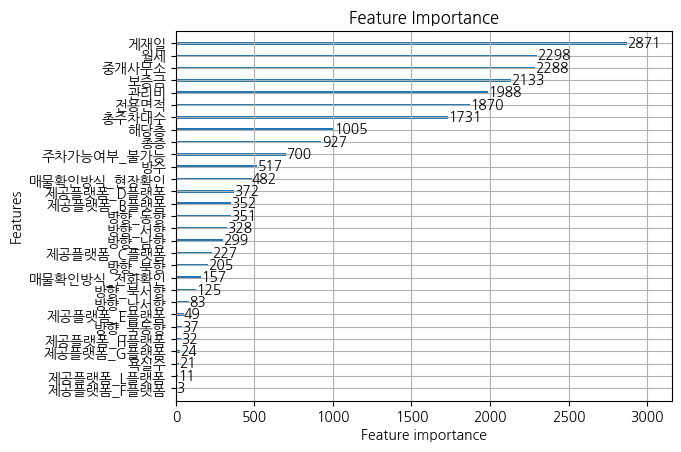

테스트 데이터 예측 결과 저장 완료.


In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder
import matplotlib as mpl

# 한글 폰트 설정
mpl.rcParams['font.family'] = 'NanumGothic'
mpl.rcParams['axes.unicode_minus'] = False
# 데이터 로드 (가정: train_data, test_data 존재)
train_data = pd.read_csv("./data/train.csv")
test_data = pd.read_csv("./data/test.csv")

# 테스트 데이터의 ID 컬럼 저장
test_ids = test_data['ID']

# 불필요한 컬럼 제거
train_data.drop(columns=['ID'], inplace=True)
test_data.drop(columns=['ID'], inplace=True)

# 날짜 컬럼 라벨 인코딩
# === 레이블 인코딩 ===
label_encode_cols = ['중개사무소', '게재일']
for col in label_encode_cols:
    le = LabelEncoder()
    combined_data = pd.concat([train_data[col], test_data[col]], axis=0).astype(str)
    le.fit(combined_data)
    train_data[col] = le.transform(train_data[col].astype(str))
    test_data[col] = le.transform(test_data[col].astype(str))

# 범주형 변수 원-핫 인코딩
categorical_cols = train_data.select_dtypes(include=['object']).columns.tolist()
train_data = pd.get_dummies(train_data, columns=categorical_cols, drop_first=True, dtype=int)
test_data = pd.get_dummies(test_data, columns=categorical_cols, drop_first=True, dtype=int)

# 컬럼 정렬 및 누락된 컬럼 처리
test_data = test_data.reindex(columns=train_data.columns.drop('허위매물여부'), fill_value=0)

# 타겟 및 피처 분리
X = train_data.drop(columns=['허위매물여부'])
y = train_data['허위매물여부']

# KNN Imputer 적용하여 결측값 처리
imputer = KNNImputer(n_neighbors=5)
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 데이터 불균형 해결 (SMOTE 적용)
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Stratified K-Fold 교차검증 설정
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# LightGBM 파라미터 설정
params = {
    'objective': 'binary',
    'metric': 'binary_logloss',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'feature_fraction': 0.9,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'verbose': -1
}

# 교차검증을 통한 모델 학습 및 평가
f1_scores = []
for train_index, valid_index in skf.split(X_resampled, y_resampled):
    X_train, X_valid = X_resampled.iloc[train_index], X_resampled.iloc[valid_index]
    y_train, y_valid = y_resampled.iloc[train_index], y_resampled.iloc[valid_index]
    
    # 모델 학습
    model = lgb.LGBMClassifier(**params, n_estimators=1000)
    model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric='binary_logloss',
        callbacks=[
            lgb.early_stopping(stopping_rounds=50),
            lgb.log_evaluation(period=100)
        ]
    )
    
    # 검증 데이터 예측 및 평가
    y_pred = model.predict(X_valid)
    f1_scores.append(f1_score(y_valid, y_pred))

# 최종 평균 F1 Score 출력
print(f"Average F1 Score: {np.mean(f1_scores):.4f}")

# 전체 데이터로 최종 모델 학습
final_model = lgb.LGBMClassifier(**params, n_estimators=1000)
final_model.fit(X_resampled, y_resampled)

# Feature Importance 시각화
plt.figure(figsize=(10, 6))
lgb.plot_importance(final_model, max_num_features=50)
plt.title("Feature Importance")
plt.show()

# 테스트 데이터 예측
test_predictions = final_model.predict(test_data)

# 결과 저장
submission = pd.DataFrame({'ID': test_ids, '허위매물여부': test_predictions})
submission.to_csv('submission.csv', index=False)
print("테스트 데이터 예측 결과 저장 완료.")

# 3등

In [ ]:
# Feature Importance 추출
feature_importances = pd.DataFrame({
    'feature': X.columns,
    'importance': final_model.feature_importances_
})

# 중요도 기준 정렬 및 하위 5개 피처 추출
low_importance_features = feature_importances.sort_values(by='importance').head(25)['feature'].tolist()
print(f"제거할 하위 5개 피처: {low_importance_features}")

# 하위 5개 피처 제거
X_filtered = X.drop(columns=low_importance_features)
test_data_filtered = test_data.drop(columns=low_importance_features)

# 데이터 불균형 해결 (SMOTE 재적용)
smote = SMOTE(random_state=42)
X_resampled_filtered, y_resampled_filtered = smote.fit_resample(X_filtered, y)

# Stratified K-Fold 교차검증 설정 및 모델 학습
f1_scores_filtered = []
for train_index, valid_index in skf.split(X_resampled_filtered, y_resampled_filtered):
    X_train, X_valid = X_resampled_filtered.iloc[train_index], X_resampled_filtered.iloc[valid_index]
    y_train, y_valid = y_resampled_filtered.iloc[train_index], y_resampled_filtered.iloc[valid_index]
    
    model_filtered = lgb.LGBMClassifier(**params, n_estimators=1000)
    model_filtered.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric='binary_logloss',
        callbacks=[
            lgb.early_stopping(stopping_rounds=50),
            lgb.log_evaluation(period=100)
        ]
    )
    y_pred_filtered = model_filtered.predict(X_valid)
    f1_scores_filtered.append(f1_score(y_valid, y_pred_filtered))

# 하위 5개 피처 제거 후 평균 F1 Score 출력
print(f"하위 5개 피처 제거 후 Average F1 Score: {np.mean(f1_scores_filtered):.4f}")

# 전체 데이터로 최종 모델 학습
final_model_filtered = lgb.LGBMClassifier(**params, n_estimators=1000)
final_model_filtered.fit(X_resampled_filtered, y_resampled_filtered)

# 테스트 데이터 예측
test_predictions_filtered = final_model_filtered.predict(test_data_filtered)

# 결과 저장 
submission_filtered = pd.DataFrame({'ID': test_ids, '허위매물여부': test_predictions_filtered})
submission_filtered.to_csv('submission_filtered.csv', index=False)
print("하위 5개 피처 제거 후 테스트 데이터 예측 결과 저장 완료.")


제거할 하위 5개 피처: ['제공플랫폼_M플랫폼', '제공플랫폼_K플랫폼', '제공플랫폼_J플랫폼', '제공플랫폼_I플랫폼', '제공플랫폼_F플랫폼', '제공플랫폼_L플랫폼', '욕실수', '제공플랫폼_G플랫폼', '제공플랫폼_H플랫폼', '방향_북동향', '제공플랫폼_E플랫폼', '방향_남서향', '방향_북서향', '매물확인방식_전화확인', '방향_북향', '제공플랫폼_C플랫폼', '방향_남향', '방향_서향', '방향_동향', '제공플랫폼_B플랫폼', '제공플랫폼_D플랫폼', '매물확인방식_현장확인', '방수', '주차가능여부_불가능', '총층']
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.0966681
[200]	valid_0's binary_logloss: 0.0783301
[300]	valid_0's binary_logloss: 0.0772831
Early stopping, best iteration is:
[273]	valid_0's binary_logloss: 0.0745728
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.0931429
[200]	valid_0's binary_logloss: 0.0650643
Early stopping, best iteration is:
[236]	valid_0's binary_logloss: 0.0622818
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.101527
[200]	valid_0's binary_logloss: 0.0879925
Early stopping, best iteration is:
[175]	valid_0's binary_

In [ ]:
final_model_filtered.feature_importances_ 

array([3808, 3434, 2944, 2273, 2996, 3613, 3561, 3461])

<Axes: title={'center': 'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

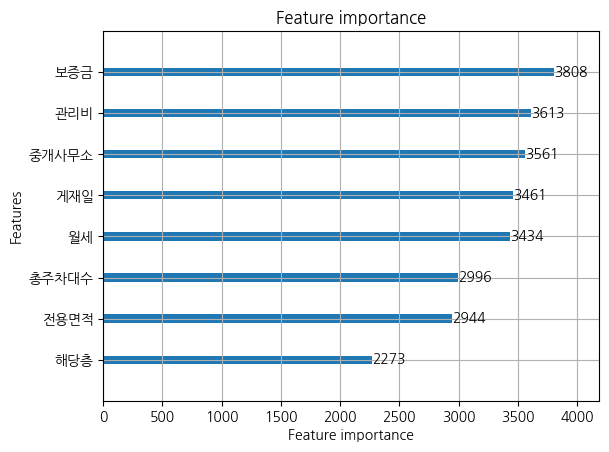

In [177]:
lgb.plot_importance(final_model_filtered, max_num_features=50)

In [ ]:
X_resampled_filtered

,보증금,월세,전용면적,해당층,총주차대수,관리비,중개사무소,게재일
0,4.025000e+08,470000.000000,27.180000,2.600000,40.000000,96.000000,256.000000,408.000000
1,1.705000e+08,200000.000000,20.102000,3.000000,14.200000,0.000000,240.000000,486.000000
2,1.140000e+08,380000.000000,29.574000,2.000000,13.000000,0.000000,157.000000,458.000000
3,1.635000e+08,30000.000000,36.300000,3.000000,13.000000,10.000000,32.000000,456.000000
4,3.460000e+08,530000.000000,25.760000,3.000000,11.800000,0.000000,76.000000,302.000000
...,...,...,...,...,...,...,...,...
4303,9.300000e+07,347154.193468,20.782548,2.877470,2.392096,2.205539,124.347829,150.976350
4304,1.486936e+07,438195.704116,27.265437,2.000000,5.841360,2.351492,262.845943,299.039917
4305,4.019656e+08,511512.010941,28.367616,2.027491,16.582820,0.123710,279.192482,185.539502
4306,2.574838e+07,316996.640715,26.847893,2.000000,11.896753,6.764614,197.456215,240.634714
